# Model evaluation and error analysis

This notebook reviews the February-selected engineered Random Forest without tuning against April. It reproduces the candidate model on January training / February validation for calibration analysis, then fits the selected model on January-March and evaluates April using the already locked threshold. It reports feature importance, calibration, confusion matrix, representative errors, and error rates across a few operationally relevant groups.

**Locked selection:** engineered Random Forest, 120 trees, maximum depth 14, minimum leaf size 40, `max_features="sqrt"`, balanced subsampling, random seed 42; threshold **0.4987978449**, selected by February validation F1. Do not select new settings from April.


In [1]:

from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "processed").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "data" / "processed").is_dir():
    raise FileNotFoundError("Open the notebook from the flight project folder.")
PAIR_PATH = ROOT / "data" / "processed" / "wn_aircraft_pairs_2026-01_to_2026-04.csv"
REPORT_DIR = ROOT / "reports" / "metrics"
ANALYSIS_DIR = ROOT / "reports" / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

VALIDATION_THRESHOLD = 0.49879784491634016


## 1. Load data and reproduce the locked model

## 1. Load data and reproduce the locked model

The February threshold is read from the saved validation comparison and checked against the locked value above. The data is separated by date before fitting any preprocessing. Engineered variables are deterministic transforms; imputers and encoders are fitted within the model pipeline on the training partition.


In [2]:

pairs = pd.read_csv(PAIR_PATH, low_memory=False, parse_dates=["FLIGHT_DATE"])
pairs["FLIGHT_DATE"] = pd.to_datetime(pairs["FLIGHT_DATE"], errors="coerce")
pairs = pairs.dropna(subset=["FLIGHT_DATE", "DEP_DEL15"]).copy()
pairs["DEP_DEL15"] = pairs["DEP_DEL15"].astype(int)

validation_table = pd.read_csv(REPORT_DIR / "day3_model_validation_comparison.csv")
rf_validation = validation_table.loc[validation_table["MODEL"].eq("Engineered random forest")]
if len(rf_validation) != 1 or not np.isclose(float(rf_validation.iloc[0]["SELECTED_THRESHOLD"]), VALIDATION_THRESHOLD):
    raise ValueError("Locked threshold does not match Day 3 February validation results.")

feb_start = pd.Timestamp("2026-02-01")
mar_start = pd.Timestamp("2026-03-01")
apr_start = pd.Timestamp("2026-04-01")
jan = pairs.loc[pairs["FLIGHT_DATE"] < feb_start].copy()
feb = pairs.loc[(pairs["FLIGHT_DATE"] >= feb_start) & (pairs["FLIGHT_DATE"] < mar_start)].copy()
jan_mar = pairs.loc[pairs["FLIGHT_DATE"] < apr_start].copy()
april = pairs.loc[pairs["FLIGHT_DATE"] >= apr_start].copy()
if any(x.empty for x in [jan, feb, jan_mar, april]):
    raise ValueError("Expected non-empty Jan training, Feb validation, Jan-Mar training, and April holdout sets.")

numeric_features = [
    "PREV_ARR_DELAY_LOG1P", "SCHEDULED_SLACK_LOG1P", "SHORT_SLACK_LT_60",
    "PREV_DELAY_X_SHORT_SLACK", "DEPARTURE_HOUR_SIN", "DEPARTURE_HOUR_COS",
]
categorical_features = ["ORIGIN", "DEST", "DAY_OF_WEEK"]
all_features = numeric_features + categorical_features

def add_engineered_features(frame):
    out = frame.copy()
    prev_delay = pd.to_numeric(out["PREV_ARR_DELAY_MIN"], errors="coerce").clip(lower=0)
    slack = pd.to_numeric(out["SCHEDULED_TURNAROUND_SLACK_MIN"], errors="coerce").clip(lower=0)
    hour = pd.to_numeric(out["DEPARTURE_HOUR_LOCAL"], errors="coerce")
    out["PREV_ARR_DELAY_LOG1P"] = np.log1p(prev_delay)
    out["SCHEDULED_SLACK_LOG1P"] = np.log1p(slack)
    out["SHORT_SLACK_LT_60"] = (slack < 60).astype("int8")
    out["PREV_DELAY_X_SHORT_SLACK"] = out["PREV_ARR_DELAY_LOG1P"] * out["SHORT_SLACK_LT_60"]
    out["DEPARTURE_HOUR_SIN"] = np.sin(2 * np.pi * hour / 24)
    out["DEPARTURE_HOUR_COS"] = np.cos(2 * np.pi * hour / 24)
    return out

engineered = add_engineered_features(pairs)

def make_model():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
    ])
    preprocess = ColumnTransformer([
        ("numeric", numeric, numeric_features),
        ("categorical", categorical, categorical_features),
    ], remainder="drop")
    forest = RandomForestClassifier(
        n_estimators=120, max_depth=14, min_samples_leaf=40,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=42,
    )
    return Pipeline([("preprocess", preprocess), ("classifier", forest)])

print("Jan rows:", len(jan), "Feb validation rows:", len(feb), "Jan-Mar rows:", len(jan_mar), "April rows:", len(april))
print("February positive rate:", round(float(feb["DEP_DEL15"].mean()),4), "April positive rate:", round(float(april["DEP_DEL15"].mean()),4))


Jan rows: 97773 Feb validation rows: 97097 Jan-Mar rows: 309576 April rows: 114084
February positive rate: 0.2201 April positive rate: 0.2558


## 2. Review probability calibration on February validation

Fit the locked model settings on January only, then inspect predicted probabilities on February. Calibration is descriptive here; do not adjust the model or threshold in this Day 4 notebook. The Brier score is mean squared probability error (lower is better). Expected calibration error (ECE) summarizes the weighted gap between predicted risk and observed frequency across quantile bins; it depends on the binning choice.


In [3]:

def calibration_table(y, probability, n_bins=10):
    data = pd.DataFrame({"actual": np.asarray(y), "probability": np.asarray(probability)})
    data["risk_bin"] = pd.qcut(data["probability"], q=n_bins, duplicates="drop")
    table = data.groupby("risk_bin", observed=True).agg(
        ROWS=("actual", "size"),
        MEAN_PREDICTED_RISK=("probability", "mean"),
        OBSERVED_DELAY_RATE=("actual", "mean"),
    ).reset_index()
    table["ABS_CALIBRATION_GAP"] = (table["MEAN_PREDICTED_RISK"] - table["OBSERVED_DELAY_RATE"]).abs()
    ece = float((table["ROWS"] / len(data) * table["ABS_CALIBRATION_GAP"]).sum())
    return table, ece

validation_model = make_model()
X_jan = engineered.loc[jan.index, all_features]
X_feb = engineered.loc[feb.index, all_features]
validation_model.fit(X_jan, jan["DEP_DEL15"])
feb_probability = validation_model.predict_proba(X_feb)[:, 1]
feb_calibration, feb_ece = calibration_table(feb["DEP_DEL15"], feb_probability)
feb_calibration.insert(0, "SPLIT", "February validation")
feb_calibration.to_csv(REPORT_DIR / "day4_february_calibration_bins.csv", index=False)
print("February Brier score:", round(brier_score_loss(feb["DEP_DEL15"], feb_probability), 4), "ECE:", round(feb_ece, 4))
print(feb_calibration.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


February Brier score: 0.1416 ECE: 0.2027
              SPLIT       risk_bin  ROWS  MEAN_PREDICTED_RISK  OBSERVED_DELAY_RATE  ABS_CALIBRATION_GAP
February validation (0.163, 0.241]  9710               0.2161               0.0358               0.1803
February validation (0.241, 0.272]  9710               0.2581               0.0517               0.2064
February validation (0.272, 0.293]  9709               0.2831               0.0592               0.2238
February validation  (0.293, 0.31]  9712               0.3018               0.0643               0.2375
February validation  (0.31, 0.329]  9708               0.3192               0.0773               0.2419
February validation (0.329, 0.359]  9710               0.3430               0.0997               0.2433
February validation (0.359, 0.408]  9709               0.3811               0.1159               0.2652
February validation (0.408, 0.546]  9709               0.4602               0.2543               0.2059
February validation (0.

## 3. Fit through March and compute the April evaluation

## 3. Fit through March and compute the April evaluation

The final model uses the same locked settings and threshold. April predictions are used for error review and reporting only; they do not drive any modeling choices.


In [4]:

final_model = make_model()
X_jan_mar = engineered.loc[jan_mar.index, all_features]
X_april = engineered.loc[april.index, all_features]
y_april = april["DEP_DEL15"]
final_model.fit(X_jan_mar, jan_mar["DEP_DEL15"])
april_probability = final_model.predict_proba(X_april)[:, 1]
april_prediction = (april_probability >= VALIDATION_THRESHOLD).astype(int)
april_confusion = confusion_matrix(y_april, april_prediction, labels=[0,1])
april_confusion_table = pd.DataFrame(
    april_confusion,
    index=["Actual under 15 min", "Actual 15+ min"],
    columns=["Predicted under 15 min", "Predicted 15+ min"],
)
april_confusion_table.to_csv(REPORT_DIR / "day4_april_confusion_matrix.csv")

april_metrics = {
    "ROWS": int(len(april)),
    "POSITIVE_RATE": float(y_april.mean()),
    "THRESHOLD": VALIDATION_THRESHOLD,
    "ACCURACY": float(accuracy_score(y_april, april_prediction)),
    "PRECISION": float(precision_score(y_april, april_prediction, zero_division=0)),
    "RECALL": float(recall_score(y_april, april_prediction, zero_division=0)),
    "F1": float(f1_score(y_april, april_prediction, zero_division=0)),
    "ROC_AUC": float(roc_auc_score(y_april, april_probability)),
    "AVERAGE_PRECISION": float(average_precision_score(y_april, april_probability)),
    "BRIER_SCORE": float(brier_score_loss(y_april, april_probability)),
}
print("Locked April metrics:", json.dumps(april_metrics, indent=2))
print("April confusion matrix:")
print(april_confusion_table.to_string())


Locked April metrics: {
  "ROWS": 114084,
  "POSITIVE_RATE": 0.2557764454261772,
  "THRESHOLD": 0.49879784491634016,
  "ACCURACY": 0.8525735423021633,
  "PRECISION": 0.6948025341192045,
  "RECALL": 0.7554489376285127,
  "F1": 0.723857684666787,
  "ROC_AUC": 0.8870397158065939,
  "AVERAGE_PRECISION": 0.8177524512203316,
  "BRIER_SCORE": 0.13317737551733472
}
April confusion matrix:
                     Predicted under 15 min  Predicted 15+ min
Actual under 15 min                   75221               9683
Actual 15+ min                         7136              22044


## 4. Interpret model feature importance

## 4. Interpret model feature importance

The Random Forest's impurity-based importance is summed by original input field so the one-hot airport levels do not appear as a long, fragmented list. These values describe how the fitted trees used features; they do not show causal effects. Importance can also favor variables with many possible values, so interpret airport and route importance carefully.


        ORIGINAL_FEATURE  IMPORTANCE
    PREV_ARR_DELAY_LOG1P      0.3733
PREV_DELAY_X_SHORT_SLACK      0.3158
      DEPARTURE_HOUR_SIN      0.1190
   SCHEDULED_SLACK_LOG1P      0.0800
       SHORT_SLACK_LT_60      0.0521
      DEPARTURE_HOUR_COS      0.0230
                  ORIGIN      0.0178
             DAY_OF_WEEK      0.0122
                    DEST      0.0067


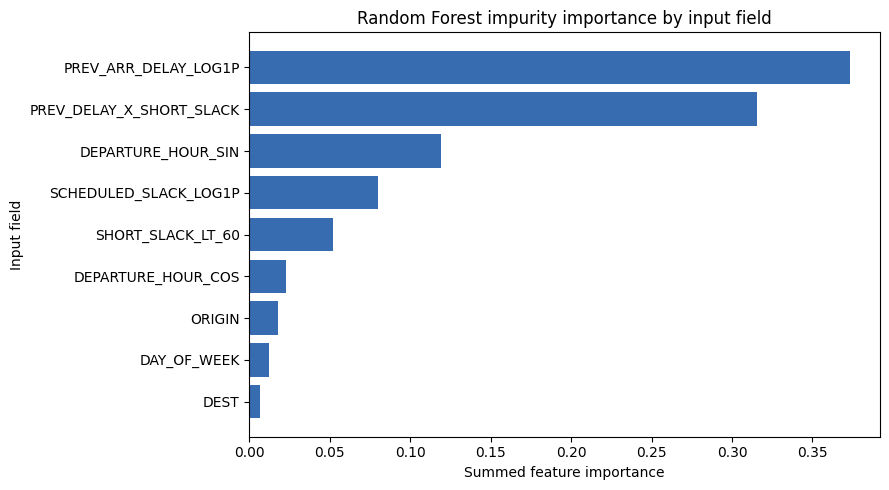

In [5]:

preprocessor = final_model.named_steps["preprocess"]
forest = final_model.named_steps["classifier"]
encoded_names = preprocessor.get_feature_names_out()
importance = pd.DataFrame({"ENCODED_FEATURE": encoded_names, "IMPORTANCE": forest.feature_importances_})

def original_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]
    for feature in numeric_features + categorical_features:
        if name == feature or name.startswith(feature + "_"):
            return feature
    return name

importance["ORIGINAL_FEATURE"] = importance["ENCODED_FEATURE"].map(original_feature)
importance = importance.sort_values("IMPORTANCE", ascending=False)
grouped_importance = importance.groupby("ORIGINAL_FEATURE", as_index=False)["IMPORTANCE"].sum().sort_values("IMPORTANCE", ascending=False)
importance.to_csv(REPORT_DIR / "day4_random_forest_encoded_importance.csv", index=False)
grouped_importance.to_csv(REPORT_DIR / "day4_random_forest_grouped_importance.csv", index=False)
print(grouped_importance.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, ax = plt.subplots(figsize=(9,5))
top = grouped_importance.sort_values("IMPORTANCE").tail(10)
ax.barh(top["ORIGINAL_FEATURE"], top["IMPORTANCE"], color="#386cb0")
ax.set(title="Random Forest impurity importance by input field", xlabel="Summed feature importance", ylabel="Input field")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day4_grouped_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Inspect false alarms and missed delays on April

## 5. Inspect false alarms and missed delays on April

False negatives are delayed flights the model missed; false positives are flights it flagged that departed under 15 minutes late. Examples are selected to make review concrete: the most delayed false negatives and the highest-risk false positives. They are illustrative cases, not a statistically representative sample.


In [6]:

error_rows = april[[
    "FLIGHT_DATE", "TAIL_NUM", "PREV_FLIGHT_DATE", "PREV_FLIGHT_NUM", "PREV_ORIGIN", "PREV_DEST",
    "PREV_ARR_DELAY_MIN", "SCHEDULED_TURNAROUND_SLACK_MIN", "FLIGHT_NUM", "ORIGIN", "DEST",
    "DEPARTURE_HOUR_LOCAL", "DEP_DELAY_MIN", "DEP_DEL15",
]].copy()
error_rows["PREDICTED_DELAY_PROBABILITY"] = april_probability
error_rows["PREDICTED_DEP_DEL15"] = april_prediction
error_rows["ERROR_TYPE"] = np.select(
    [(error_rows["DEP_DEL15"].eq(1) & error_rows["PREDICTED_DEP_DEL15"].eq(0)),
     (error_rows["DEP_DEL15"].eq(0) & error_rows["PREDICTED_DEP_DEL15"].eq(1))],
    ["False negative", "False positive"],
    default="Correct",
)
false_negatives = error_rows.loc[error_rows["ERROR_TYPE"].eq("False negative")].nlargest(12, "DEP_DELAY_MIN")
false_positives = error_rows.loc[error_rows["ERROR_TYPE"].eq("False positive")].nlargest(12, "PREDICTED_DELAY_PROBABILITY")
error_examples = pd.concat([false_negatives, false_positives], ignore_index=True)
error_examples.to_csv(REPORT_DIR / "day4_april_error_examples.csv", index=False)
print("Most severe false negatives:")
print(false_negatives.to_string(index=False))
print("Highest-risk false positives:")
print(false_positives.to_string(index=False))


Most severe false negatives:
FLIGHT_DATE TAIL_NUM PREV_FLIGHT_DATE  PREV_FLIGHT_NUM PREV_ORIGIN PREV_DEST  PREV_ARR_DELAY_MIN  SCHEDULED_TURNAROUND_SLACK_MIN  FLIGHT_NUM ORIGIN DEST  DEPARTURE_HOUR_LOCAL  DEP_DELAY_MIN  DEP_DEL15  PREDICTED_DELAY_PROBABILITY  PREDICTED_DEP_DEL15     ERROR_TYPE
 2026-04-24   N8704Q       2026-04-23           3288.0         AUS       SJC                10.0                           390.0         104    SJC  DEN                     6          654.0          1                     0.189636                    0 False negative
 2026-04-03   N7821L       2026-04-02            659.0         DEN       SEA                26.0                           475.0        4065    SEA  OAK                     6          642.0          1                     0.210774                    0 False negative
 2026-04-14   N8677A       2026-04-13           1647.0         PHX       ORD                62.0                           380.0        4646    ORD  LAS                     

## 6. Check error rates by inbound delay and slack

## 6. Check error rates by inbound delay and slack

These April group summaries help reveal where the locked model struggles. They are diagnostic only; do not change the model using these results. Group rates may be unstable when a group contains few flights, so always read the row count.


In [7]:

april_diagnostics = april[["PREV_ARR_DELAY_MIN", "SCHEDULED_TURNAROUND_SLACK_MIN", "DEP_DEL15"]].copy()
april_diagnostics["PREDICTED_DEP_DEL15"] = april_prediction
april_diagnostics["PREV_DELAY_BAND"] = pd.cut(
    april_diagnostics["PREV_ARR_DELAY_MIN"],
    bins=[-np.inf,0,15,30,60,120,np.inf],
    labels=["<=0","1-15","16-30","31-60","61-120",">120"],
    include_lowest=True,
)
april_diagnostics["SLACK_BAND"] = pd.cut(
    april_diagnostics["SCHEDULED_TURNAROUND_SLACK_MIN"],
    bins=[0,15,30,60,90,120,180,360,720,1440],
    labels=["0-15","16-30","31-60","61-90","91-120","121-180","181-360","361-720","721-1440"],
    include_lowest=True,
)

def summarize_errors(group_column):
    return april_diagnostics.groupby(group_column, observed=False).apply(
        lambda g: pd.Series({
            "FLIGHTS": len(g),
            "ACTUAL_DELAY_RATE": g["DEP_DEL15"].mean(),
            "PREDICTED_DELAY_RATE": g["PREDICTED_DEP_DEL15"].mean(),
            "RECALL": recall_score(g["DEP_DEL15"], g["PREDICTED_DEP_DEL15"], zero_division=0),
            "PRECISION": precision_score(g["DEP_DEL15"], g["PREDICTED_DEP_DEL15"], zero_division=0),
        }), include_groups=False
    ).reset_index()

by_inbound_error = summarize_errors("PREV_DELAY_BAND")
by_slack_error = summarize_errors("SLACK_BAND")
by_inbound_error.to_csv(REPORT_DIR / "day4_april_errors_by_inbound_delay.csv", index=False)
by_slack_error.to_csv(REPORT_DIR / "day4_april_errors_by_slack.csv", index=False)
print("Errors by previous arrival delay:")
print(by_inbound_error.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("Errors by scheduled slack:")
print(by_slack_error.to_string(index=False, float_format=lambda x: f"{x:.3f}"))


Errors by previous arrival delay:
PREV_DELAY_BAND   FLIGHTS  ACTUAL_DELAY_RATE  PREDICTED_DELAY_RATE  RECALL  PRECISION
            <=0 67378.000              0.092                 0.016   0.114      0.644
           1-15 22693.000              0.329                 0.589   0.840      0.470
          16-30 10629.000              0.606                 0.739   0.971      0.796
          31-60  8380.000              0.693                 0.728   0.975      0.928
         61-120  3759.000              0.665                 0.671   0.963      0.955
           >120  1245.000              0.622                 0.645   0.956      0.922
Errors by scheduled slack:
SLACK_BAND   FLIGHTS  ACTUAL_DELAY_RATE  PREDICTED_DELAY_RATE  RECALL  PRECISION
      0-15   688.000              0.863                 0.969   0.980      0.873
     16-30  1600.000              0.618                 0.752   0.887      0.728
     31-60 81005.000              0.303                 0.336   0.795      0.715
     61-90  7

## Evaluation conclusions and limits

## Day 4 conclusions and limits

- The model was not changed or retuned using April. The February-selected threshold remains fixed.
- Feature importance is descriptive, not causal; aircraft rotation constraints, weather, staffing, airport capacity, schedule changes, and other operational conditions are missing or incomplete in this dataset.
- Error examples are selected cases. Use subgroup counts and rates, not anecdotes alone, to describe performance.
- The final result applies to Southwest domestic flights in this four-month sample and should not be generalized to other airlines or periods without new validation.


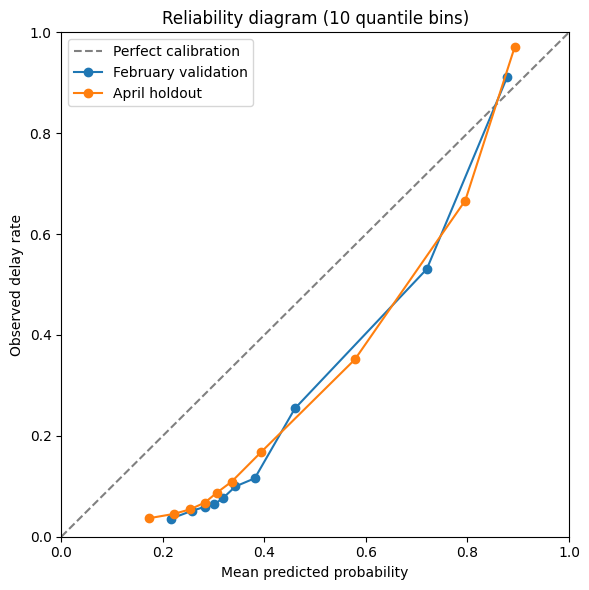

Calibration summary:
                              SPLIT   ROWS  POSITIVE_RATE  BRIER_SCORE    ECE
February validation (Jan-fit model)  97097         0.2201       0.1416 0.2027
  April holdout (Jan-Mar-fit model) 114084         0.2558       0.1332 0.1832
Day 4 reports written to C:\Users\Aditi Chauhan\Documents\ChatGPT\flight collision prediction model\reports


In [8]:

calibration_report = pd.DataFrame([
    {"SPLIT":"February validation (Jan-fit model)", "ROWS":len(feb), "POSITIVE_RATE":feb["DEP_DEL15"].mean(), "BRIER_SCORE":brier_score_loss(feb["DEP_DEL15"],feb_probability), "ECE":feb_ece},
    {"SPLIT":"April holdout (Jan-Mar-fit model)", "ROWS":len(april), "POSITIVE_RATE":april["DEP_DEL15"].mean(), "BRIER_SCORE":brier_score_loss(april["DEP_DEL15"],april_probability), "ECE":calibration_table(april["DEP_DEL15"],april_probability)[1]},
])
calibration_report.to_csv(REPORT_DIR / "day4_calibration_metrics.csv", index=False)

# Reliability diagram: validation and final test are shown separately.
april_calibration, april_ece = calibration_table(april["DEP_DEL15"], april_probability)
april_calibration.insert(0,"SPLIT","April holdout")
calibration_all = pd.concat([feb_calibration, april_calibration], ignore_index=True)
calibration_all.to_csv(REPORT_DIR / "day4_calibration_bins.csv", index=False)
fig, ax = plt.subplots(figsize=(6,6))
ax.plot([0,1],[0,1],linestyle="--",color="gray",label="Perfect calibration")
for name, table in [("February validation",feb_calibration),("April holdout",april_calibration)]:
    ax.plot(table["MEAN_PREDICTED_RISK"],table["OBSERVED_DELAY_RATE"],marker="o",label=name)
ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean predicted probability",ylabel="Observed delay rate",title="Reliability diagram (10 quantile bins)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day4_calibration_curve.png",dpi=160,bbox_inches="tight")
plt.show()

# Write a concise audit note containing reproducibility facts and report inventory.
summary={
    "selected_model":"Engineered Random Forest",
    "locked_threshold":VALIDATION_THRESHOLD,
    "candidate_fit_period":"January 2026",
    "threshold_validation_period":"February 2026",
    "final_fit_period":"January-March 2026",
    "final_evaluation_period":"April 2026",
    "model_settings":{"n_estimators":120,"max_depth":14,"min_samples_leaf":40,"max_features":"sqrt","class_weight":"balanced_subsample","random_state":42},
    "april_metrics":april_metrics,
    "calibration":calibration_report.to_dict(orient="records"),
    "grouped_feature_importance":grouped_importance.to_dict(orient="records"),
    "error_examples_count":int(len(error_examples)),
    "outputs":[
        "reports/metrics/day4_calibration_metrics.csv","reports/metrics/day4_calibration_bins.csv",
        "reports/metrics/day4_random_forest_grouped_importance.csv","reports/metrics/day4_random_forest_encoded_importance.csv",
        "reports/metrics/day4_april_confusion_matrix.csv","reports/metrics/day4_april_error_examples.csv",
        "reports/metrics/day4_april_errors_by_inbound_delay.csv","reports/metrics/day4_april_errors_by_slack.csv",
        "reports/figures/day4_calibration_curve.png","reports/figures/day4_grouped_feature_importance.png",
        "reports/metrics/day4_run_summary.json","reports/analysis/day4_error_analysis.md",
    ],
}
(REPORT_DIR/"day4_run_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")

lines=[
    "# Model evaluation and error analysis", "",
    "## Locked evaluation", "",
    f"Selected model: {summary['selected_model']}; threshold: {VALIDATION_THRESHOLD:.4f}, chosen on February validation. April was not used for model or threshold selection.", "",
    "April results:", "",
    "| Metric | Value |", "|---|---:|",
]
for key,label in [("ACCURACY","Accuracy"),("PRECISION","Precision"),("RECALL","Recall"),("F1","F1"),("ROC_AUC","ROC-AUC"),("AVERAGE_PRECISION","Average precision"),("BRIER_SCORE","Brier score")]:
    lines.append(f"| {label} | {april_metrics[key]:.4f} |")
lines += ["", "## Calibration", "", f"February validation Brier score: {brier_score_loss(feb['DEP_DEL15'],feb_probability):.4f}; ECE: {feb_ece:.4f}.", f"April descriptive Brier score: {brier_score_loss(april['DEP_DEL15'],april_probability):.4f}; ECE: {april_ece:.4f}. Calibration is not adjusted in this review.", "", "## Leading grouped feature importances", "", "| Input field | Importance |", "|---|---:|"]
for row in grouped_importance.head(8).itertuples(index=False): lines.append(f"| {row.ORIGINAL_FEATURE} | {row.IMPORTANCE:.4f} |")
lines += ["", "## Limitations", "", "Importance is not causal evidence. April errors are retrospective cases, and this BTS subset lacks complete weather, crew, airport capacity, and real-time schedule information. The examples and subgroup tables are diagnostic only; no April-based model changes were made."]
(ANALYSIS_DIR/"day4_error_analysis.md").write_text(chr(10).join(lines)+chr(10),encoding="utf-8")
print("Calibration summary:")
print(calibration_report.to_string(index=False,float_format=lambda x:f"{x:.4f}"))
print("Model evaluation reports written to",REPORT_DIR)
